<h1 align ='center' style='color:white'>Credit Risk Modelling Project</h1>

<h3 align ='center' style='color:yellow'>Data Collection and Cleaning</h3>

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import average
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)

In [101]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [102]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [103]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [104]:
df = pd.merge(df, df_bureau)
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10


In [105]:
df['default'] = df['default'].astype(int)
df.default.value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

In [106]:
X = df.drop('default', axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [107]:
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

df_train.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,C12747,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,0
32495,C32496,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,0
43675,C43676,38,M,Single,Salaried,3195000,0,Mortgage,26,Chennai,...,2023-12-04,2023-12-29,1,1,54,12,67,4,0,0
9040,C09041,42,M,Married,Salaried,1500000,2,Mortgage,30,Bangalore,...,2020-06-18,2020-07-07,3,0,76,0,0,8,87,0
13077,C13078,58,M,Married,Self-Employed,1817000,4,Owned,29,Pune,...,2020-11-12,2020-12-07,1,2,60,0,0,1,71,0


In [108]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 47
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [109]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [110]:
mode_residence = df_train.residence_type.mode()[0]
mode_residence

'Owned'

In [111]:
df_train.residence_type = df_train.residence_type.fillna(mode_residence)

In [112]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str

In [113]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='str')

In [114]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address',
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement',
                      'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                      'total_dpd', 'enquiry_count', 'credit_utilization_ratio']


columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city',
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']


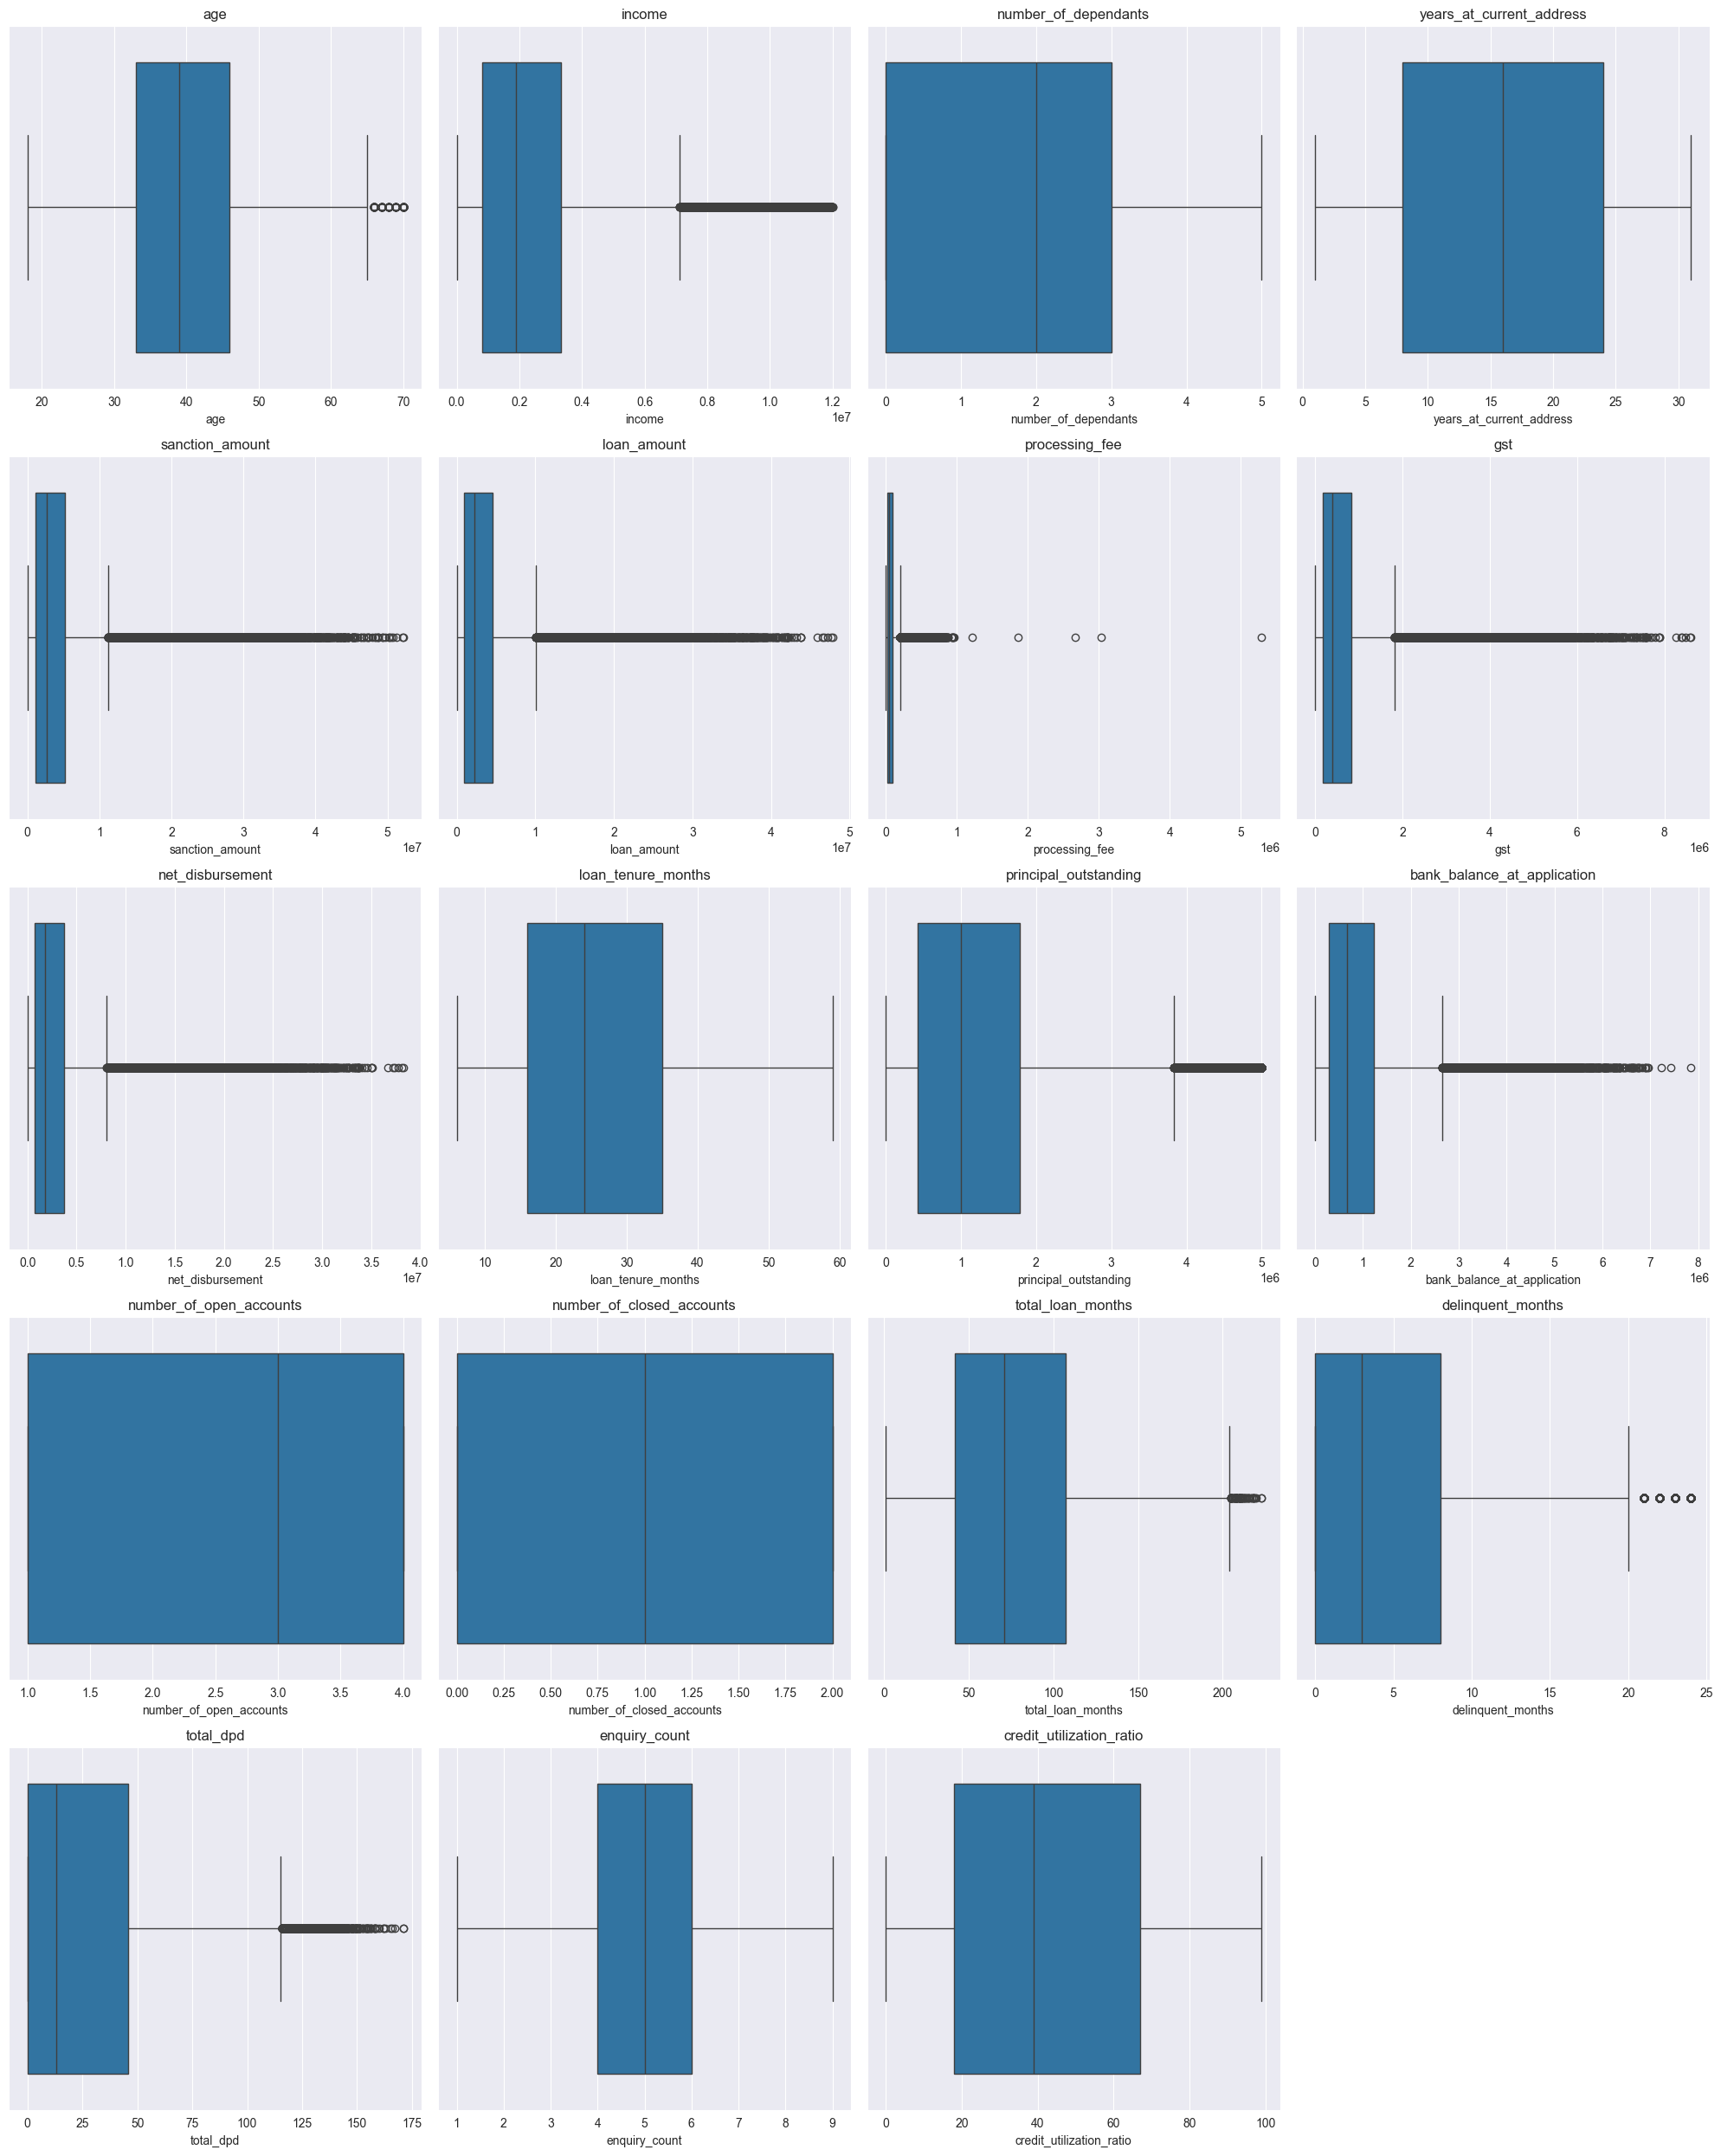

In [115]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


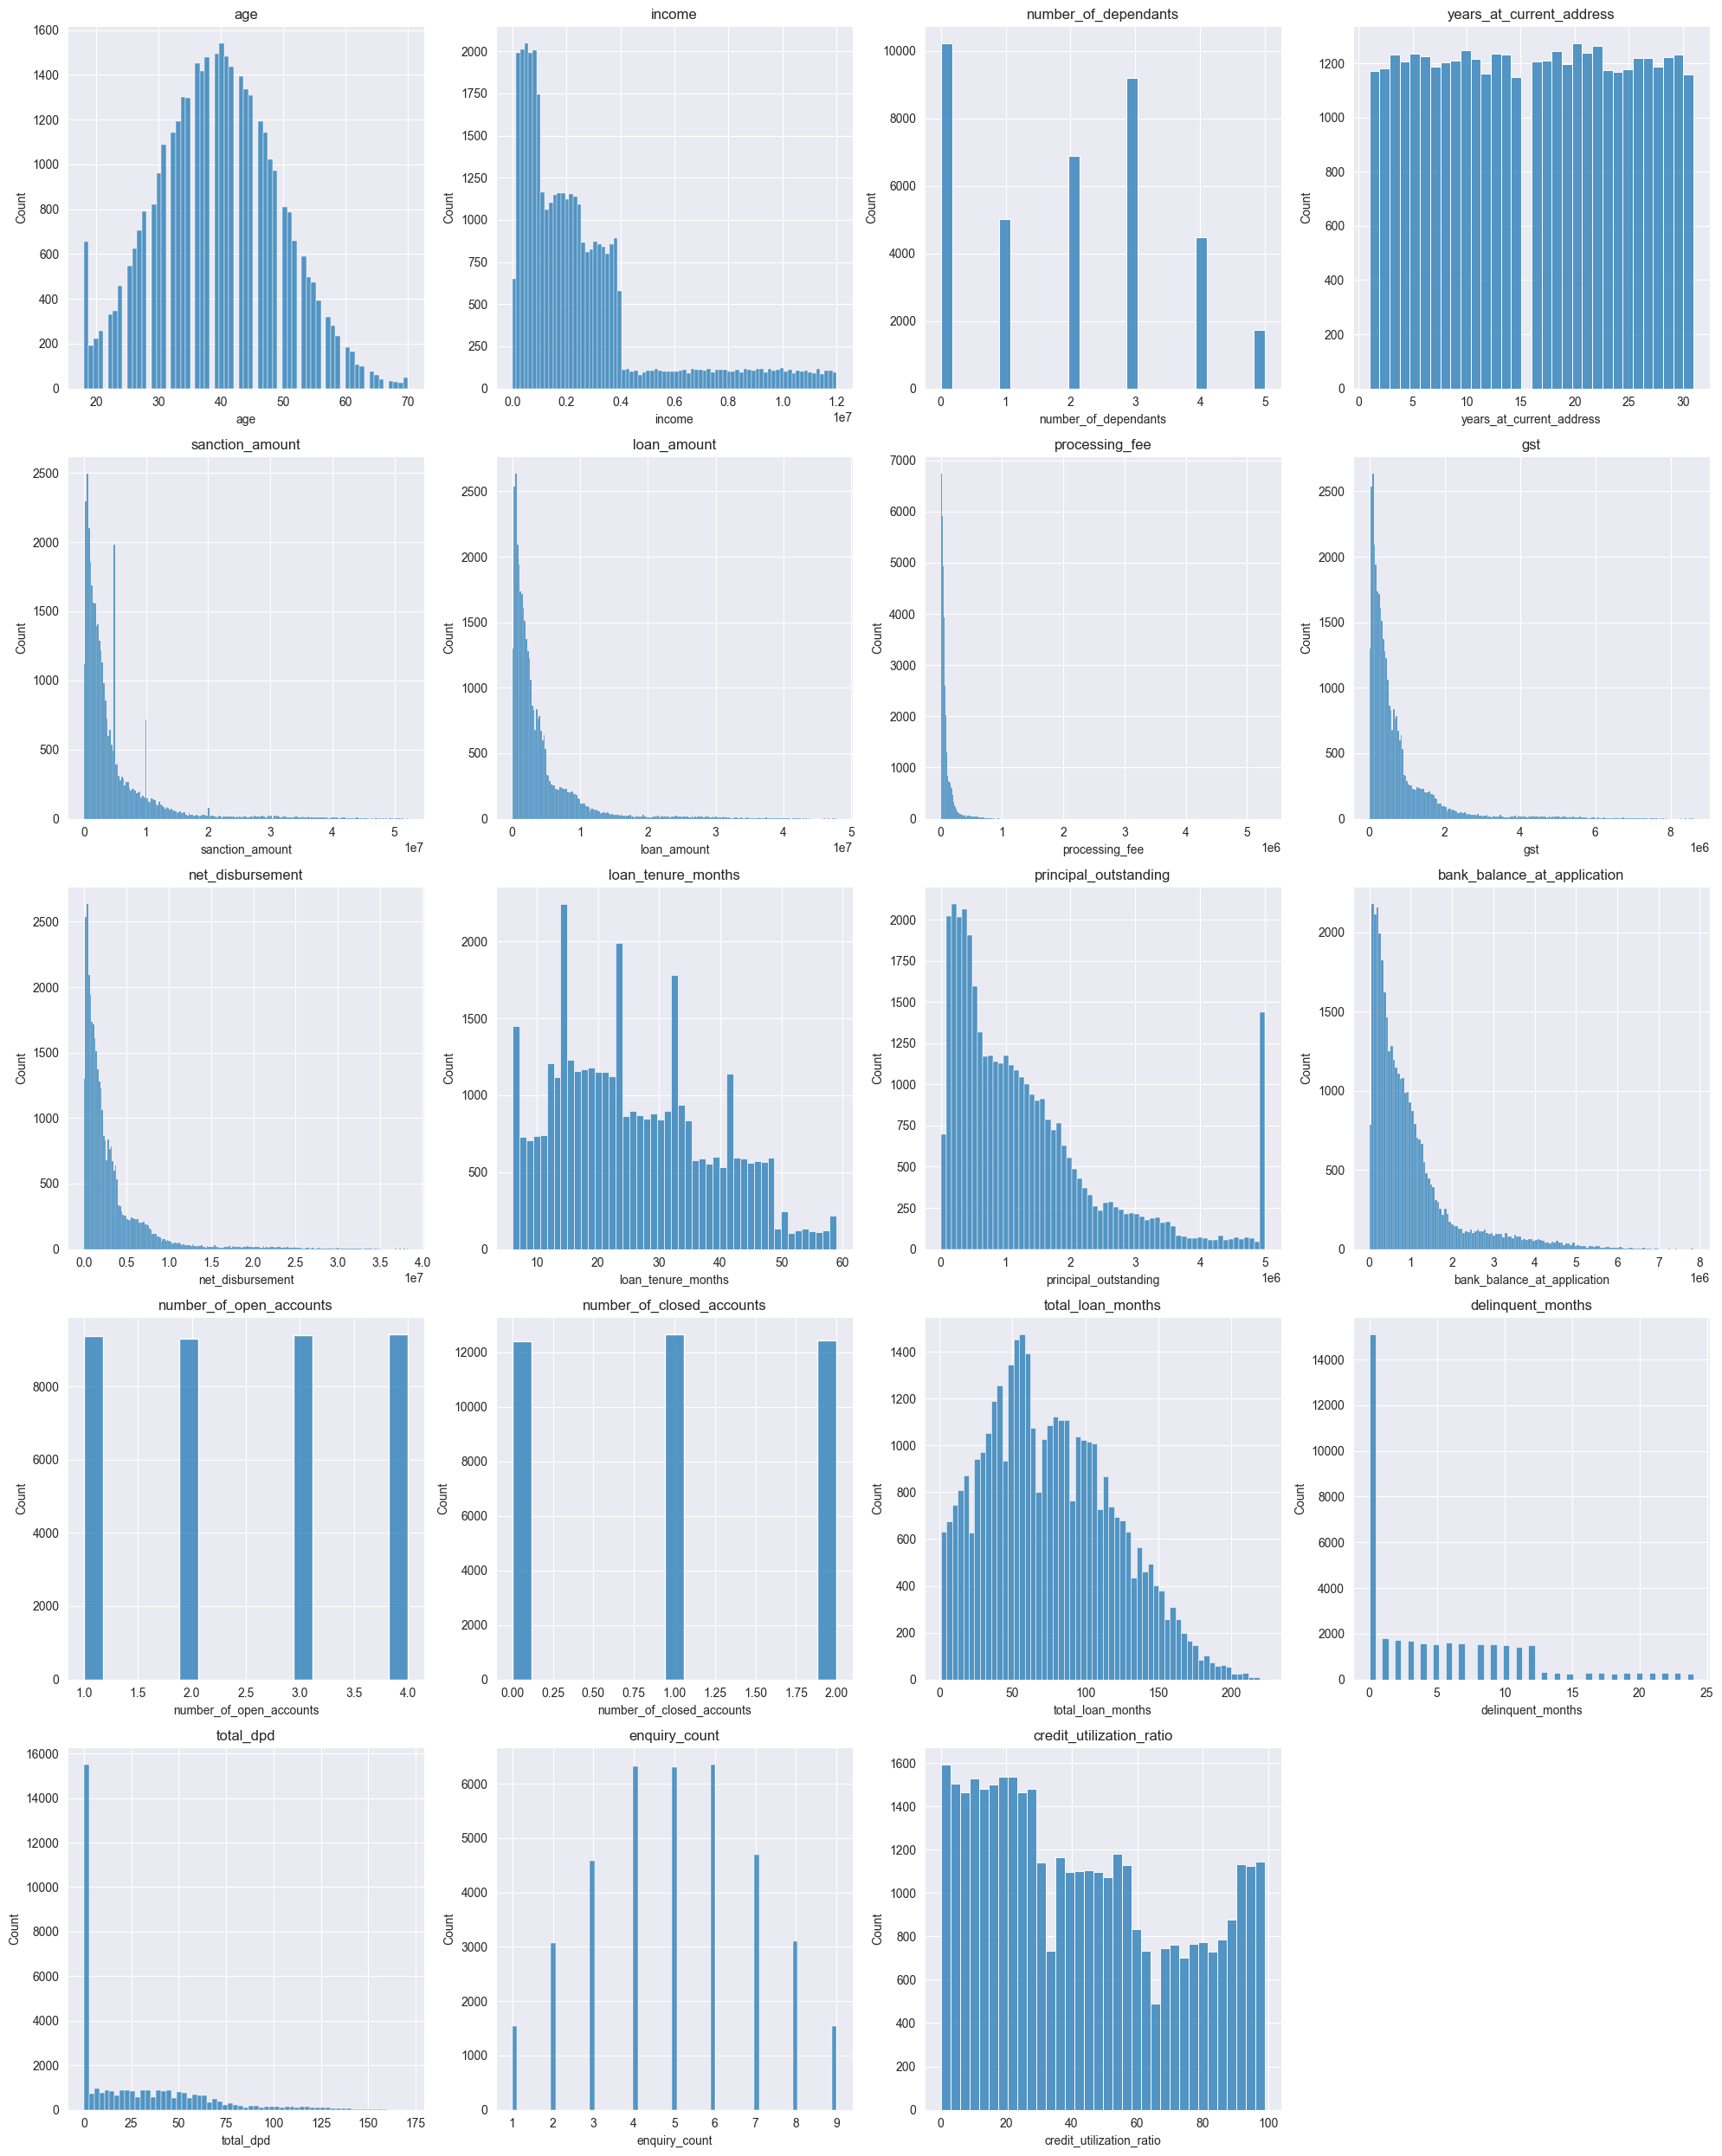

In [116]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.histplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [117]:
df_train.processing_fee.describe()

count     37500.00
mean      80290.68
std      113128.14
min           0.00
25%       19220.00
50%       44600.00
75%       92420.00
max     5293543.52
Name: processing_fee, dtype: float64

In [118]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
23981,2234000,2669791.02
28174,966000,1214492.67
47089,1738000,1858964.77
29305,2616000,3036378.01
9898,3626000,5293543.52


In [119]:
df_train_1 = df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()
df_train_1[(df_train_1.processing_fee/df_train_1.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee


In [120]:
df_test = df_test[(df_test.processing_fee/df_test.loan_amount)<0.03].copy()
df_test.shape

(12497, 33)

In [121]:
for col in columns_categorical:
    print(col, "-->", df_train_1[col].unique())

gender --> <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
marital_status --> <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str
employment_status --> <ArrowStringArray>
['Self-Employed', 'Salaried']
Length: 2, dtype: str
residence_type --> <ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str
city --> <ArrowStringArray>
['Hyderabad',    'Mumbai',   'Chennai', 'Bangalore',      'Pune',   'Kolkata',
 'Ahmedabad',     'Delhi',   'Lucknow',    'Jaipur']
Length: 10, dtype: str
state --> <ArrowStringArray>
[    'Telangana',   'Maharashtra',    'Tamil Nadu',     'Karnataka',
   'West Bengal',       'Gujarat',         'Delhi', 'Uttar Pradesh',
     'Rajasthan']
Length: 9, dtype: str
zipcode --> [500001 400001 600001 560001 411001 700001 380001 110001 226001 302001]
loan_purpose --> <ArrowStringArray>
['Home', 'Education', 'Personal', 'Auto', 'Personaal']
Length: 5, dtype: str
loan_type --> <ArrowStringArray>
['Secured', 'Unsecured']
Length: 2, dtype: str
def

In [122]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')

<h3 align ='center' style='color:yellow'>Exploratory Data Analysis</h3>

In [123]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

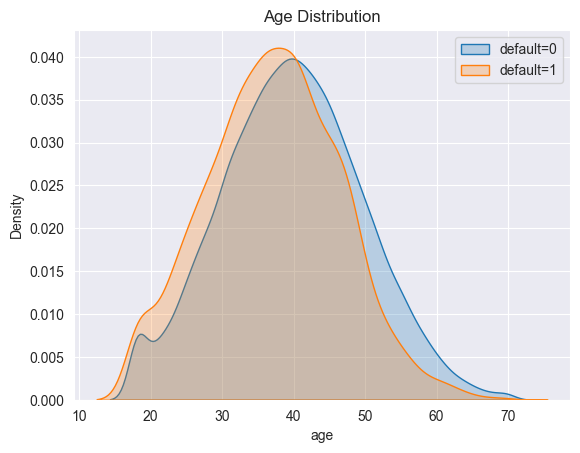

In [124]:
sns.kdeplot(df_train_1['age'][df_train_1['default']==0], fill=True, label='default=0')
sns.kdeplot(df_train_1['age'][df_train_1['default']==1], fill=True, label='default=1')
plt.title('Age Distribution')
plt.legend()
plt.xlabel('age')
plt.show()

Insights:-
1. Orange graph is little bit shifted to the left of blue graph which indicates that people with young age are more likely to default.

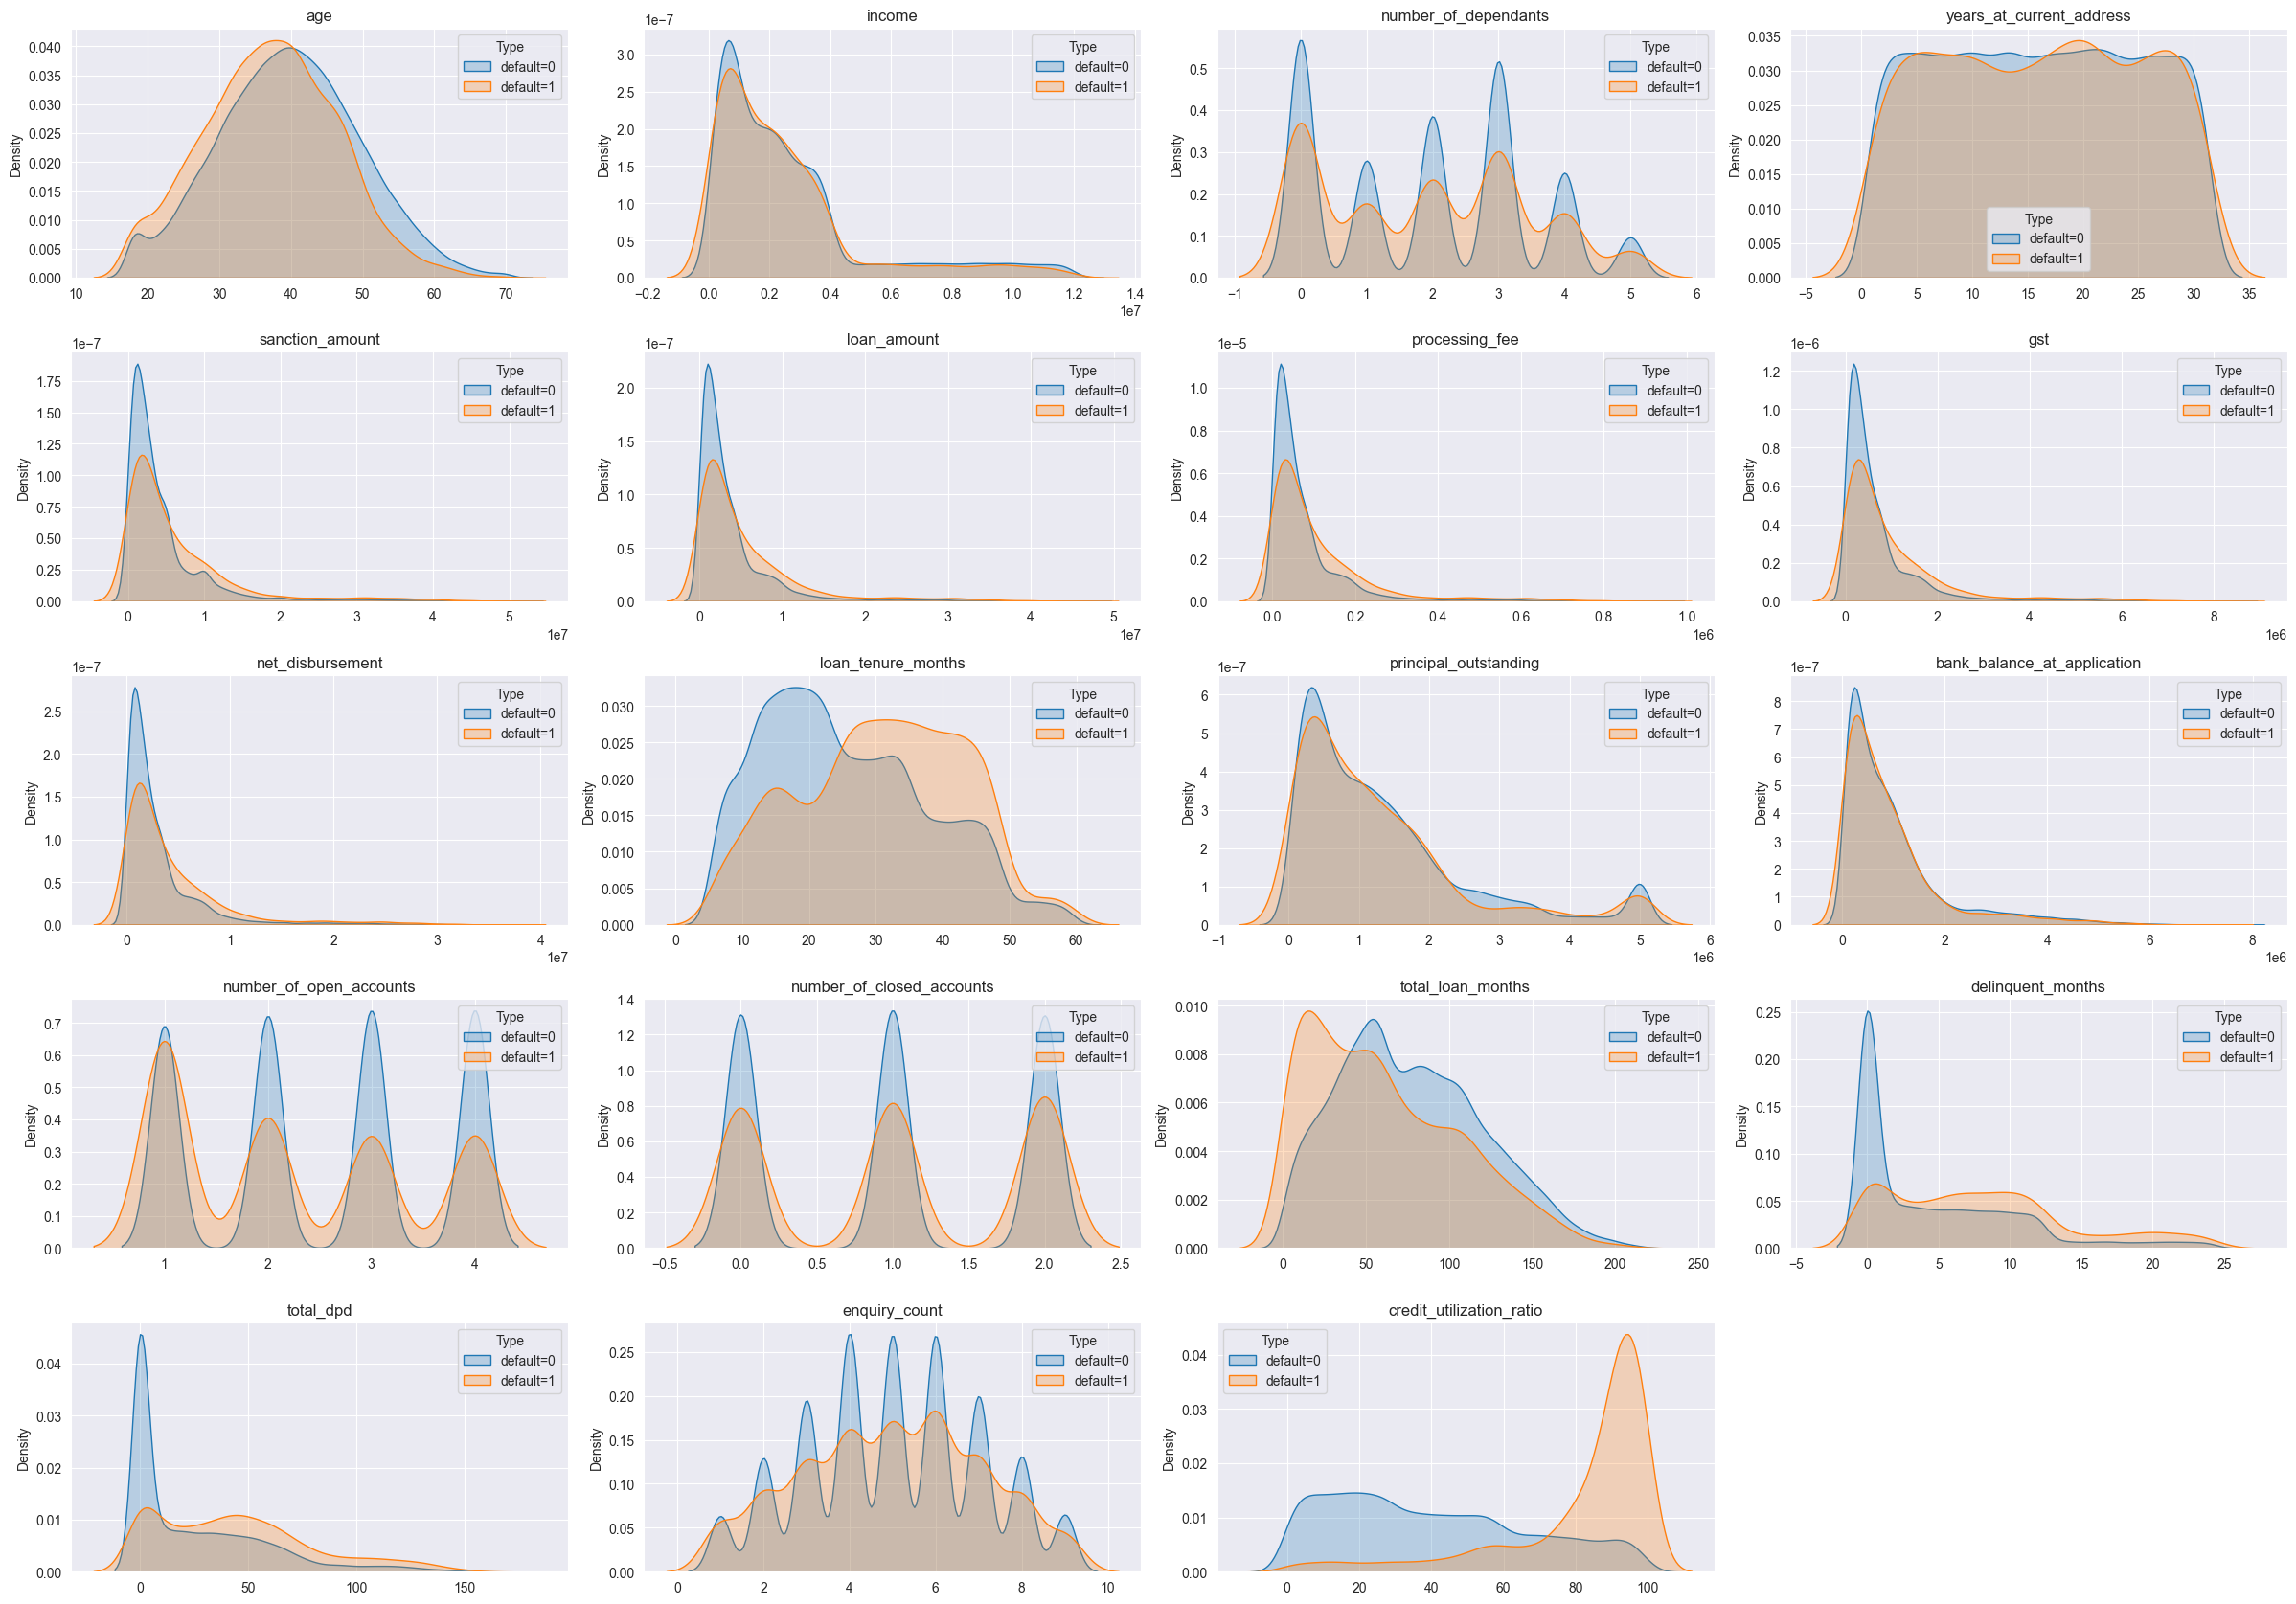

In [125]:
plt.figure(figsize=(24, 20)) # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1) # 1 row, 4 columns, ith subplot
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.legend(title='Type')
    plt.title(col)
    plt.xlabel('')

plt.tight_layout()
plt.show()

Insights

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence, these 4 looks like strong predictors
2. In remaining columns the distributions do not give any obvious insights
3. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later


<h3 align ='center' style='color:yellow'>Feature Engineering</h3>

In [126]:
df_train_1['loan_to_income'] = round(df_train_1['loan_amount']/df_train_1['income'], 2)
df_test['loan_to_income'] = round(df_test['loan_amount']/df_test['income'], 2)

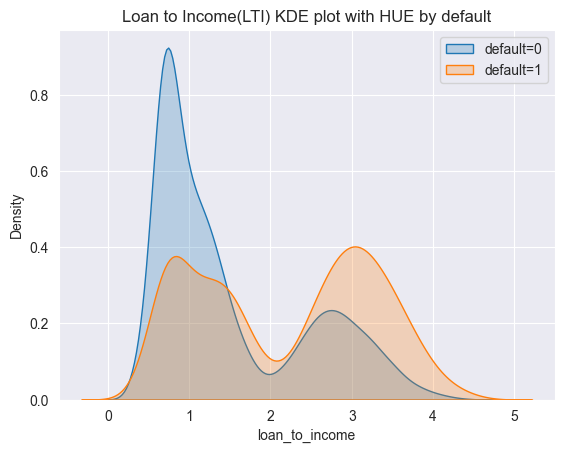

In [127]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['loan_to_income'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['loan_to_income'], fill=True, label='default=1')
plt.title(f'Loan to Income(LTI) KDE plot with HUE by default')
plt.legend()
plt.show()

In [128]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income'],
      dtype='str')

In [129]:
df_train_1['delinquency_ratio'] = round(df_train_1['delinquent_months']*100/df_train_1['total_loan_months'], 1)
df_train_1[['delinquent_months', 'total_loan_months', 'delinquency_ratio']].head(3)
df_train_1['delinquency_ratio'].describe()

count   37488.00
mean       10.33
std        17.30
min         0.00
25%         0.00
50%         3.70
75%        12.90
max       100.00
Name: delinquency_ratio, dtype: float64

In [130]:
df_test['delinquency_ratio'] = round(df_test['delinquent_months']*100/df_test['total_loan_months'], 1)

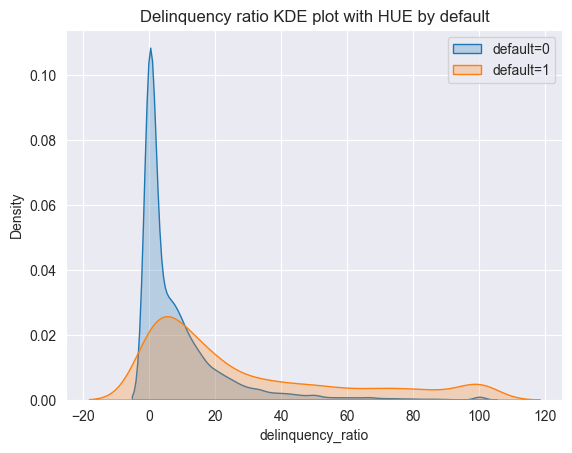

In [131]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['delinquency_ratio'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['delinquency_ratio'], fill=True, label='default=1')
plt.title(f'Delinquency ratio KDE plot with HUE by default')
plt.legend()
plt.show()

In [132]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
    df_train_1['delinquent_months']!=0,
    round(df_train_1['total_dpd']/df_train_1['delinquent_months'], 1),
    0)
df_train_1[['total_dpd', 'delinquent_months', 'avg_dpd_per_delinquency']].head(3)
df_train_1['avg_dpd_per_delinquency'].describe()

count   37488.00
mean        3.28
std         2.91
min         0.00
25%         0.00
50%         4.30
75%         5.72
max        10.00
Name: avg_dpd_per_delinquency, dtype: float64

In [133]:
df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months']!=0,
    round(df_test['total_dpd']/df_test['delinquent_months'], 1),
    0)

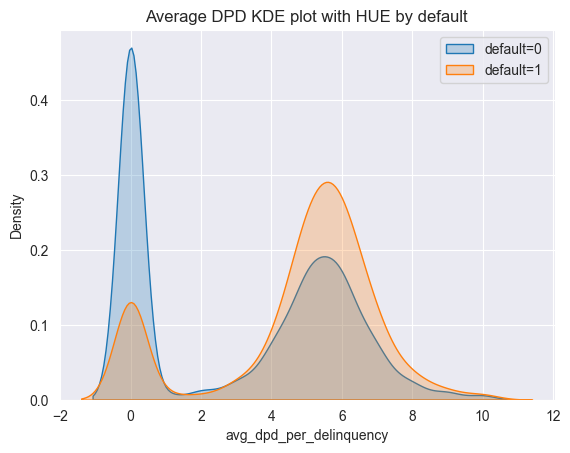

In [134]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['avg_dpd_per_delinquency'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['avg_dpd_per_delinquency'], fill=True, label='default=1')
plt.title(f'Average DPD KDE plot with HUE by default')
plt.legend()
plt.show()

In [135]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

<h3 align ='center' style='color:yellow'>Feature Selection</h3>

In [136]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id'], axis=1).copy()
df_test = df_test.drop(['cust_id', 'loan_id'], axis=1)

In [137]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                            'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)
df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                        'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)


In [138]:
df_train_3.info()

<class 'pandas.DataFrame'>
Index: 37488 entries, 12746 to 37784
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          37488 non-null  int64  
 1   gender                       37488 non-null  str    
 2   marital_status               37488 non-null  str    
 3   employment_status            37488 non-null  str    
 4   number_of_dependants         37488 non-null  int64  
 5   residence_type               37488 non-null  str    
 6   years_at_current_address     37488 non-null  int64  
 7   city                         37488 non-null  str    
 8   state                        37488 non-null  str    
 9   zipcode                      37488 non-null  int64  
 10  loan_purpose                 37488 non-null  str    
 11  loan_type                    37488 non-null  str    
 12  sanction_amount              37488 non-null  int64  
 13  processing_fee              

In [139]:
cols_to_scale = df_train_3.select_dtypes(['int64', 'float64'])
cols_to_scale = cols_to_scale.drop(['default', 'zipcode'], axis=1).columns
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [140]:
X_train = df_train_3.drop('default', axis=1)
y_train = df_train_3['default']

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00
mean,0.41,0.39,0.50,418876.24,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.10,0.33
std,0.19,0.31,0.30,169029.87,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,110001.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.40,0.40,0.50,400001.00,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.67,0.50,0.50,0.39,0.20,0.04,0.43
75%,0.54,0.60,0.77,560001.00,0.10,0.10,0.10,0.10,0.55,0.35,0.16,1.00,1.00,0.62,0.68,0.51,0.13,0.57
max,1.00,1.00,1.00,700001.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [141]:
X_test = df_test.drop('default', axis=1)
y_test = df_test['default']

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00
mean,0.42,0.38,0.50,419759.82,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.11,0.33
std,0.19,0.31,0.30,168845.35,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,110001.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.42,0.40,0.50,411001.00,0.05,0.05,0.05,0.05,0.34,0.20,0.08,0.33,0.50,0.50,0.39,0.20,0.04,0.44
75%,0.54,0.60,0.77,560001.00,0.10,0.09,0.09,0.09,0.55,0.36,0.16,0.67,1.00,0.62,0.68,0.50,0.13,0.58
max,1.00,1.00,1.00,700001.00,0.98,0.96,0.96,0.96,1.00,1.00,0.94,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [142]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Variable'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

In [143]:
calculate_vif(X_train[cols_to_scale])

F:\PyCharm 2025.1.2\projects\.venv\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Variable,VIF
0,age,5.55
1,number_of_dependants,2.72
2,years_at_current_address,3.36
3,sanction_amount,101.08
4,processing_fee,inf
5,gst,inf
6,net_disbursement,inf
7,loan_tenure_months,6.17
8,principal_outstanding,16.32
9,bank_balance_at_application,9.33


In [144]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding']
X_train_1 = X_train.drop(features_to_drop_vif, axis=1)
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [145]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Variable,VIF
0,age,5.53
1,number_of_dependants,2.73
2,years_at_current_address,3.45
3,zipcode,5.61
4,loan_tenure_months,6.03
5,bank_balance_at_application,1.81
6,number_of_open_accounts,4.36
7,number_of_closed_accounts,2.39
8,enquiry_count,6.44
9,credit_utilization_ratio,2.95


In [146]:
selected_numeric_features_vif = vif_df.Variable.values
selected_numeric_features_vif

<ArrowStringArray>
[                        'age',        'number_of_dependants',
    'years_at_current_address',                     'zipcode',
          'loan_tenure_months', 'bank_balance_at_application',
     'number_of_open_accounts',   'number_of_closed_accounts',
               'enquiry_count',    'credit_utilization_ratio',
              'loan_to_income',           'delinquency_ratio',
     'avg_dpd_per_delinquency']
Length: 13, dtype: str

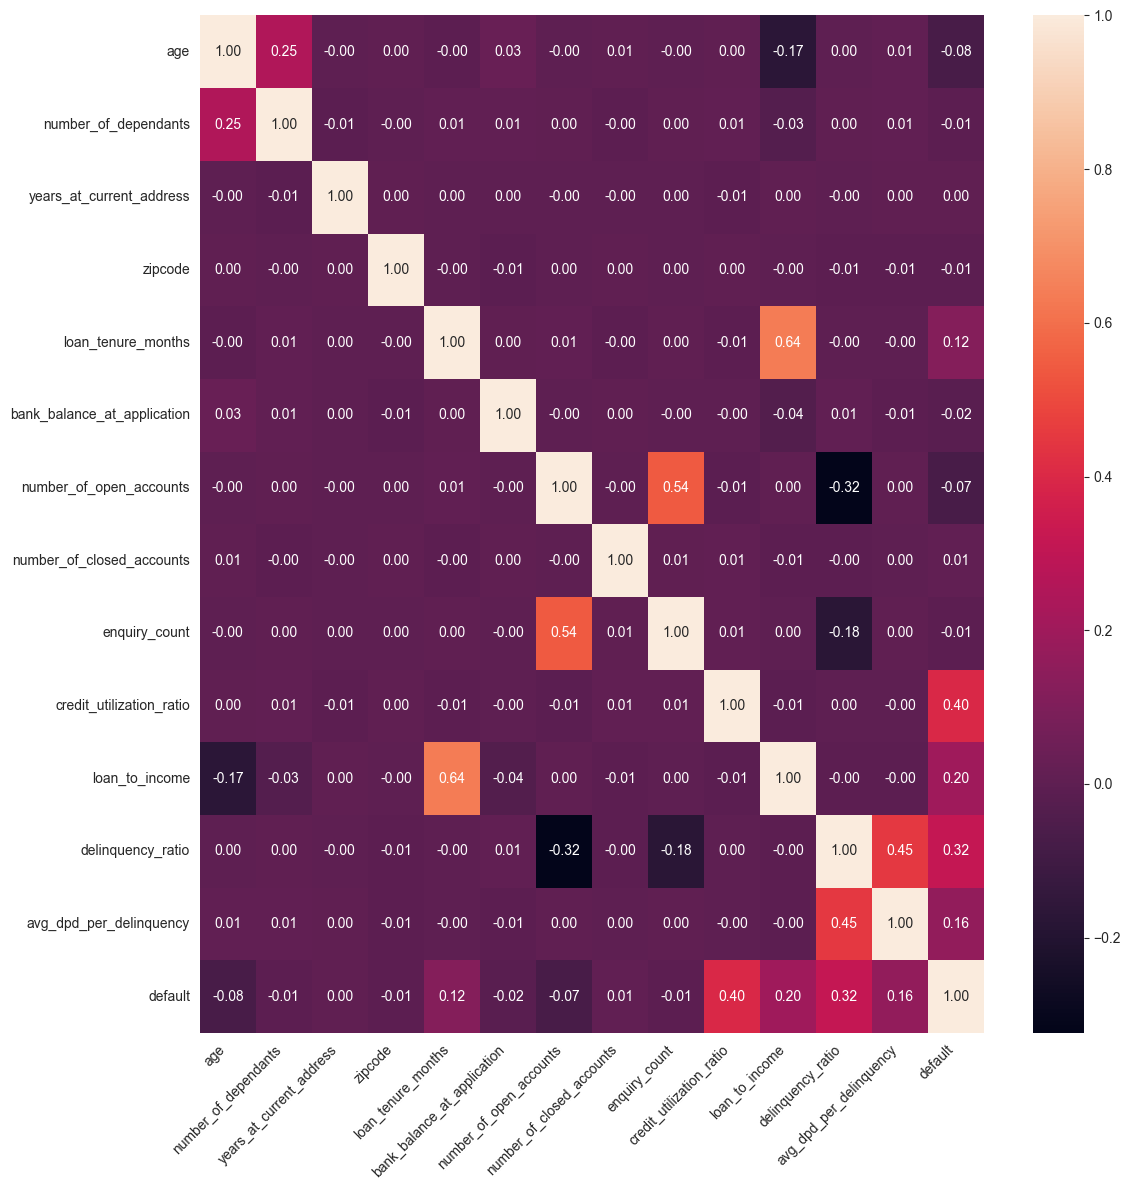

In [147]:
plt.figure(figsize=(12,12))
cm = df_train_3[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [148]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [149]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count', 'sum'])
    grouped = grouped.rename(columns={'count':'total', 'sum':'good'})
    grouped['bad'] = grouped['total'] - grouped['good']

    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    grouped['good_pct'] = grouped['good']/ total_good
    grouped['bad_pct'] = grouped['bad']/ total_bad
    grouped['woe'] = np.log(grouped['good_pct']/grouped['bad_pct'])
    grouped['iv'] = grouped['woe'] * (grouped['good_pct'] - grouped['bad_pct'])

    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)

    total_iv = grouped['iv'].sum()
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), 'loan_purpose', 'default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7447,327,7120,0.10,0.21,-0.72,0.08
Education,5620,559,5061,0.17,0.15,0.16,0.00
Home,11304,1734,9570,0.54,0.28,0.66,0.17
Personal,13117,603,12514,0.19,0.37,-0.67,0.12


In [150]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == 'str':
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), feature, 'default')
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train], axis=1), feature, 'default')
    iv_values[feature] = iv

iv_values

{'age': np.float64(0.0890689462679479),
 'gender': np.float64(0.00047449502170914947),
 'marital_status': np.float64(0.001129766845390142),
 'employment_status': np.float64(0.003953046301722585),
 'number_of_dependants': np.float64(0.0019380899135053508),
 'residence_type': np.float64(0.246745268718145),
 'years_at_current_address': np.float64(0.0020800513608156363),
 'city': np.float64(0.0019059578709781529),
 'state': np.float64(0.0019005589806779287),
 'zipcode': np.float64(0.0016677413243392572),
 'loan_purpose': np.float64(0.3691197842282755),
 'loan_type': np.float64(0.16319324904149224),
 'loan_tenure_months': np.float64(0.21893515090196278),
 'bank_balance_at_application': np.float64(0.0063187993277516365),
 'number_of_open_accounts': np.float64(0.08463134083005877),
 'number_of_closed_accounts': np.float64(0.0011964272592421567),
 'enquiry_count': np.float64(0.007864214085342608),
 'credit_utilization_ratio': np.float64(2.352965568168245),
 'loan_to_income': np.float64(0.47641

In [151]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.353
19,delinquency_ratio,0.717
18,loan_to_income,0.476
20,avg_dpd_per_delinquency,0.402
10,loan_purpose,0.369
5,residence_type,0.247
12,loan_tenure_months,0.219
11,loan_type,0.163
0,age,0.089
14,number_of_open_accounts,0.085


In [152]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

<h3 align ='center' style='color:yellow'>Feature Encoding</h3>

In [153]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [154]:
X_train_reduced.head()

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
12746,0.788,Owned,Home,Secured,0.415,1.000,0.364,0.415,0.132,0.590
32495,0.500,Owned,Education,Secured,0.830,0.667,0.051,0.307,0.062,0.620
43675,0.385,Mortgage,Home,Secured,0.491,0.000,0.000,0.759,0.222,0.560
9040,0.462,Mortgage,Education,Secured,0.642,0.667,0.879,0.194,0.000,0.000
13077,0.769,Owned,Personal,Unsecured,0.170,0.000,0.717,0.047,0.000,0.000


In [155]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)

X_train_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788,0.415,1.000,0.364,0.415,0.132,0.590,True,False,False,True,False,False
32495,0.500,0.830,0.667,0.051,0.307,0.062,0.620,True,False,True,False,False,False
43675,0.385,0.491,0.000,0.000,0.759,0.222,0.560,False,False,False,True,False,False
9040,0.462,0.642,0.667,0.879,0.194,0.000,0.000,False,False,True,False,False,False
13077,0.769,0.170,0.000,0.717,0.047,0.000,0.000,True,False,False,False,True,True


<h3 align ='center' style='color:yellow'>Model Training</h3>

## Attempt 1:
    1. Logistic Regression, Random forest, XG boost
    2. No handling of class imbalance

In [156]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_curve
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.72      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [157]:
model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.71      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [158]:
model = XGBClassifier()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.81      0.76      0.79      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.87      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [159]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': np.logspace(-4, 4, 20), # Logarithmically spaced values from 10^-4 to 10^4
    'solver': ['lbfgs', 'saga', 'liblinear', 'newton-cg'] # Algorithm to use in the optimization problem
}

# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=10000) # Increased max_iter for convergence

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=50, # Number of parameter settings that are sampled
    scoring='f1',
    cv=3, # 5-fold cross-validation
    verbose=2,
    random_state=42, # Set a random state for reproducibility
    n_jobs=-1 # Use all available cores
)

# Fit the RandomizedSearchCV to the training data_and_notebooks
random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'solver': 'liblinear', 'C': np.float64(1438.44988828766)}
Best Score: 0.7578820896729832
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     11423
           1       0.83      0.74      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.86      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [160]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators':[100,150,200,250,300],
    'max_depth':[3,4,5,6,7,8,9,10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight':[1,2,3,5,7,10],
    'reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0], # L1 regularization term
    'reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0] # L2 regularization term
}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_dist, n_iter=100,
                                   scoring='f1', cv=3, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.8, 'scale_pos_weight': 2, 'reg_lambda': 1.0, 'reg_alpha': 5.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.9}
Best Score: 0.7897818450696698
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.77      0.83      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.88      0.90      0.89     12497
weighted avg       0.97      0.96      0.96     12497



## Attempt 2:
    1. Logistic Regression, Random forest, XG boost
    2. Handling of class imbalance by undersampling

In [161]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_encoded, y_train)
y_train_rus.value_counts()

default
0    3223
1    3223
Name: count, dtype: int64

In [162]:
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.51      0.96      0.67      1074

    accuracy                           0.92     12497
   macro avg       0.75      0.93      0.81     12497
weighted avg       0.95      0.92      0.93     12497



## Attempt 3:
    1. Logistic Regression
    2. Handle class imbalance by SMOTE Tomek
    3. Parameter tuning using Optuna

In [163]:
smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    34195
1    34195
Name: count, dtype: int64

In [164]:
model = LogisticRegression()
model.fit(X_train_smt, y_train_smt)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.55      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [165]:
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

In [166]:
def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }

    model = LogisticRegression(**param, max_iter=10000)

    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(objective, n_trials=50)

[I 2026-08-19 11:34:22,835] A new study created in memory with name: no-name-61e836a2-b4fa-4ff7-baf3-8cff5aabe482
[I 2026-08-19 11:34:28,743] Trial 0 finished with value: 0.767736800302251 and parameters: {'C': 2.9458890320985565, 'solver': 'lbfgs', 'tol': 0.0896956697343124, 'class_weight': None}. Best is trial 0 with value: 0.767736800302251.
[I 2026-08-19 11:34:31,958] Trial 1 finished with value: 0.8063437488545141 and parameters: {'C': 0.06100547901718137, 'solver': 'lbfgs', 'tol': 0.05132326579202468, 'class_weight': None}. Best is trial 1 with value: 0.8063437488545141.
[I 2026-08-19 11:34:35,333] Trial 2 finished with value: 0.9457350530857235 and parameters: {'C': 1.9453462849549072, 'solver': 'saga', 'tol': 0.0002541582184063009, 'class_weight': None}. Best is trial 2 with value: 0.9457350530857235.
[I 2026-08-19 11:34:38,783] Trial 3 finished with value: 0.9308879697454975 and parameters: {'C': 0.011331624498630415, 'solver': 'saga', 'tol': 0.00017860962172459342, 'class_wei

In [167]:
print('Best trial:')
trial = study_logistic.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)


Best trial:
  F1-score: 0.945837800631191
  Params: 
    C: 1.8990346721991254
    solver: lbfgs
    tol: 6.283097427590917e-05
    class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



## Attempt 4:
    1. XG Boost
    2. Handle class imbalance by SMOTE Tomek
    3. Parameter tuning using Optuna

In [168]:
# Define the objective function for Optuna
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model = XGBClassifier(**param)

    # Calculate the cross-validated f1_score
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective, n_trials=50)


[I 2026-08-19 11:39:21,415] A new study created in memory with name: no-name-ed201c89-e02e-4824-9484-3c6b4a0b2b35
[I 2026-08-19 11:39:23,174] Trial 0 finished with value: 0.945261509136115 and parameters: {'lambda': 3.965113911530486, 'alpha': 0.1486894241445097, 'subsample': 0.6242782263508697, 'colsample_bytree': 0.5630336636021355, 'max_depth': 7, 'eta': 0.04387806551356212, 'gamma': 3.2597119389049043, 'scale_pos_weight': 3.3895547315115637, 'min_child_weight': 6, 'max_delta_step': 2}. Best is trial 0 with value: 0.945261509136115.
[I 2026-08-19 11:39:24,204] Trial 1 finished with value: 0.9400791012594619 and parameters: {'lambda': 1.0967534589856365, 'alpha': 0.09961298446526178, 'subsample': 0.4580877280165887, 'colsample_bytree': 0.8843940482113986, 'max_depth': 5, 'eta': 0.05370676654893496, 'gamma': 1.5817486559000882, 'scale_pos_weight': 6.794637926562224, 'min_child_weight': 10, 'max_delta_step': 2}. Best is trial 0 with value: 0.945261509136115.
[I 2026-08-19 11:39:25,468]

In [169]:
print('Best trial:')
trial = study_xgb.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_params = study_xgb.best_params
best_model_xgb = XGBClassifier(**best_params)
best_model_xgb.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)


Best trial:
  F1-score: 0.9735262477382652
  Params: 
    lambda: 4.24697069193499
    alpha: 0.0010423813076408136
    subsample: 0.4998561156708763
    colsample_bytree: 0.6735571179561461
    max_depth: 9
    eta: 0.16817653939178864
    gamma: 0.4899897538280022
    scale_pos_weight: 1.6678231734558617
    min_child_weight: 7
    max_delta_step: 2
              precision    recall  f1-score   support

           0       0.99      0.96      0.98     11423
           1       0.68      0.88      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.84      0.92      0.87     12497
weighted avg       0.96      0.96      0.96     12497



## Finally, we are going with best model of Logistic regression as the recall is above 90% as per client's requirement

<h3 align ='center' style='color:yellow'>Model Evaluation</h3>

In [171]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [175]:
from sklearn.metrics import roc_curve, auc

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, probabilities)
fpr[:10], tpr[:10], thresholds[:10]

(array([0.        , 0.        , 0.        , 0.00008754, 0.00008754,
        0.00017509, 0.00017509, 0.00026263, 0.00026263, 0.00035017]),
 array([0.        , 0.0009311 , 0.16294227, 0.16294227, 0.17783985,
        0.17783985, 0.21880819, 0.21880819, 0.23277467, 0.23277467]),
 array([       inf, 1.        , 0.99935847, 0.99932673, 0.99920181,
        0.99920043, 0.99859054, 0.99857462, 0.99818773, 0.99817818]))

In [176]:
area = auc(fpr, tpr)
area

0.9836790780011774

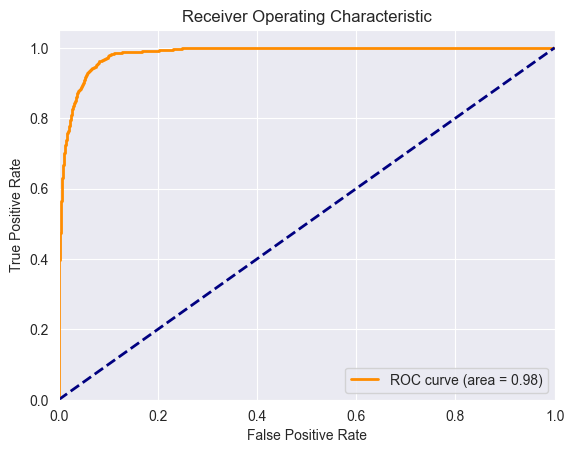

In [177]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

## Model Evaluation: rank order & KS Statistic

In [179]:
best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval = pd.DataFrame({
    'Default Truth':y_test,
    'Default Probability': probabilities
})

df_eval

,Default Truth,Default Probability
19205,0,0.548
15514,0,0.000
30367,0,0.007
35347,0,0.008
41814,1,0.926
...,...,...
29297,0,0.001
20567,0,0.000
681,0,0.003
33682,0,0.826


In [183]:
df_eval['Decile'] = pd.qcut(df_eval['Default Probability'], 10, labels=False, duplicates='drop')
df_eval.head()

,Default Truth,Default Probability,decile,Decile
19205,0,0.548,8,8
15514,0,0.000,2,2
30367,0,0.007,6,6
35347,0,0.008,6,6
41814,1,0.926,9,9


In [184]:
df_grouped = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),
}))
df_grouped.reset_index(inplace=True)
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,0.000,0.000,0.000,1250.000
1,1,0.000,0.000,0.000,1250.000
2,2,0.000,0.000,0.000,1249.000
3,3,0.000,0.000,0.000,1250.000
4,4,0.000,0.001,0.000,1250.000
5,5,0.001,0.005,0.000,1249.000
6,6,0.005,0.032,5.000,1245.000
7,7,0.032,0.220,11.000,1238.000
8,8,0.220,0.817,160.000,1090.000
9,9,0.817,1.000,898.000,352.000


In [185]:
df_grouped.sort_values('Decile', ascending=False, inplace=True)
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events
9,9,0.817,1.000,898.000,352.000
8,8,0.220,0.817,160.000,1090.000
7,7,0.032,0.220,11.000,1238.000
6,6,0.005,0.032,5.000,1245.000
5,5,0.001,0.005,0.000,1249.000
4,4,0.000,0.001,0.000,1250.000
3,3,0.000,0.000,0.000,1250.000
2,2,0.000,0.000,0.000,1249.000
1,1,0.000,0.000,0.000,1250.000
0,0,0.000,0.000,0.000,1250.000


In [186]:
df_grouped['Event Rate'] = df_grouped['Events']*100 / (df_grouped['Events']+df_grouped['Non-events'])
df_grouped['Non-event Rate'] = df_grouped['Non-events']*100 / (df_grouped['Events']+df_grouped['Non-events'])
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
9,9,0.817,1.000,898.000,352.000,71.840,28.160
8,8,0.220,0.817,160.000,1090.000,12.800,87.200
7,7,0.032,0.220,11.000,1238.000,0.881,99.119
6,6,0.005,0.032,5.000,1245.000,0.400,99.600
5,5,0.001,0.005,0.000,1249.000,0.000,100.000
4,4,0.000,0.001,0.000,1250.000,0.000,100.000
3,3,0.000,0.000,0.000,1250.000,0.000,100.000
2,2,0.000,0.000,0.000,1249.000,0.000,100.000
1,1,0.000,0.000,0.000,1250.000,0.000,100.000
0,0,0.000,0.000,0.000,1250.000,0.000,100.000


In [187]:
df_grouped['Cum Events'] =  df_grouped['Events'].cumsum()
df_grouped['Cum Non-events'] =  df_grouped['Non-events'].cumsum()
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events
9,9,0.817,1.000,898.000,352.000,71.840,28.160,898.000,352.000
8,8,0.220,0.817,160.000,1090.000,12.800,87.200,1058.000,1442.000
7,7,0.032,0.220,11.000,1238.000,0.881,99.119,1069.000,2680.000
6,6,0.005,0.032,5.000,1245.000,0.400,99.600,1074.000,3925.000
5,5,0.001,0.005,0.000,1249.000,0.000,100.000,1074.000,5174.000
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000


In [188]:
df_grouped['Cum Event Rate'] = df_grouped['Cum Events'] * 100 / df_grouped['Events'].sum()
df_grouped['Cum Non-event Rate'] = df_grouped['Cum Non-events']*100 / df_grouped['Non-events'].sum()
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate
9,9,0.817,1.000,898.000,352.000,71.840,28.160,898.000,352.000,83.613,3.082
8,8,0.220,0.817,160.000,1090.000,12.800,87.200,1058.000,1442.000,98.510,12.624
7,7,0.032,0.220,11.000,1238.000,0.881,99.119,1069.000,2680.000,99.534,23.461
6,6,0.005,0.032,5.000,1245.000,0.400,99.600,1074.000,3925.000,100.000,34.361
5,5,0.001,0.005,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000


In [191]:
df_grouped['KS'] = abs(df_grouped['Cum Event Rate'] - df_grouped['Cum Non-event Rate'])
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
9,9,0.817,1.000,898.000,352.000,71.840,28.160,898.000,352.000,83.613,3.082,80.531
8,8,0.220,0.817,160.000,1090.000,12.800,87.200,1058.000,1442.000,98.510,12.624,85.887
7,7,0.032,0.220,11.000,1238.000,0.881,99.119,1069.000,2680.000,99.534,23.461,76.073
6,6,0.005,0.032,5.000,1245.000,0.400,99.600,1074.000,3925.000,100.000,34.361,65.639
5,5,0.001,0.005,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295,54.705
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237,43.763
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180,32.820
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114,21.886
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057,10.943
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000,0.000


KS ValueThe highest KS value is 85.88%, found at Decile 8. This indicates that the model's performance in distinguishing between events and non-events is most significant at this decile. (If KS is in top 3 decile and score above 40, it is considered a good predictive model.)

In [193]:
gini_coeff = 2*area -1
print('AUC', area)
print('Gini Coefficient', gini_coeff)

AUC 0.9836790780011774
Gini Coefficient 0.9673581560023548


AUC of 0.98: The model is very good at distinguishing between events and non-events.Gini coefficient of 0.96: This further confirms that the model is highly effective in its predictions, with almost perfect rank ordering capability.The Gini coefficient ranges from -1 to 1, where a value closer to 1 signifies a perfect model, 0 indicates a model with no discriminative power, and -1 signifies a perfectly incorrect model.

<h3 align ='center' style='color:yellow'>Model Finalization</h3>

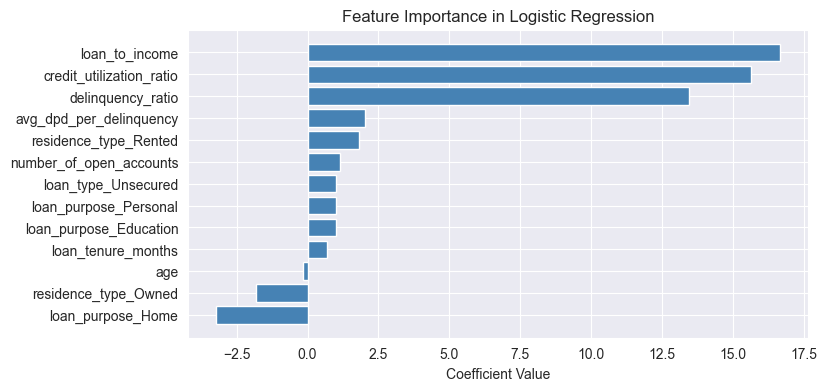

In [189]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

<h3 align ='center' style='color:yellow'>Saving the Model</h3>

In [194]:
X_test_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346,0.755,0.333,0.990,0.550,0.000,0.000,True,False,False,True,False,False
15514,0.481,0.226,1.000,0.323,0.220,0.000,0.000,True,False,True,False,False,False
30367,0.231,0.547,0.667,0.828,0.180,0.000,0.000,True,False,False,False,False,False
35347,0.365,0.755,1.000,0.485,0.571,0.024,0.700,True,False,False,True,False,False
41814,0.577,0.717,0.667,0.980,0.407,0.107,0.640,False,False,False,True,False,False


In [195]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [196]:
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [197]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [201]:
from joblib import dump

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns,
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}
dump(model_data, '../info/artifacts/model_data.joblib')

['artifacts/model_data.joblib']

In [202]:
final_model.coef_, final_model.intercept_

(array([[-0.15620023,  0.66974795,  1.14497264, 15.63881638, 16.6670525 ,
         13.45908776,  2.02282021, -1.81432148,  1.81580725,  1.0059318 ,
         -3.21553885,  1.01838503,  1.01838503]]),
 array([-20.26559982]))